# 09 — Estados afetivos: os agrupamentos refletem o estado afetivo autodeclarado no RAB2?
Rótulos individuais recebidos da orientadora (09/10/2026), em `data/rotulos_afetivos_rab2.csv`. Pela regra da tese,
vêm da **nota de polaridade (1–5) atribuída à música** ouvida logo antes do RAB2: > 3 positivo, = 3 neutro, < 3 negativo.

Nos 38 participantes com sinal: **33 positivos, 3 negativos (P5, P17, P25) e 2 neutros (P27, P34)**. Com só 5 casos
fora da classe positiva, o ARI com o rótulo é pouco informativo (um cluster de 5 pessoas teria de coincidir
exatamente com eles). Por isso, além de ARI/NMI, as perguntas são feitas de forma adequada a uma **classe rara**:
1. o rótulo se confunde com diagnóstico, sexo, duração do relato, amplitude ou limpeza da ICA?
2. **clusters × afeto**: ARI/NMI (3 classes) e Fisher exato (positivo × não positivo) em todos os agrupamentos;
   **enriquecimento**: os não positivos se concentram em algum cluster (incluindo o subgrupo de lentificação)?
3. **anomalia**: os não positivos são atípicos no espaço de atributos (distância ao centro, LOF)?
4. **por atributo**: Mann-Whitney + FDR, índices de lentificação e assimetria frontal alfa (exploratório);
5. **referência supervisionada** (só descritiva): regressão logística LOSO, AUC com IC95% e teste de permutação.

Base principal: `v2_full_semF4` (ICLabel + escala de amplitude, sem F4). Sensibilidade: `v0` (19 canais, mínimo).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score

from src.data_io import ROOT, SCALP_CHANNELS, REGION, load_metadata
from src.pipeline import load_variant, load_numericos
from src.features import subject_distribution_features
from src.clustering import to_pca, balance_windows, k_sweep, best_k, algorithms
from src.selection import drop_quasi_constant, select_unsupervised
from src.evaluation import external_metrics, majority_vote, mann_whitney_fdr, auc_ci, loso_logreg

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
ID = ["subject", "group", "sex", "window"]
BASES = ["v2_full_semF4", "v0"]

meta = load_metadata()
AFF = meta.set_index("subject")["affect_rab2"]
POS = meta.set_index("subject")["affect_pos"]
NONPOS = sorted(POS[POS == "nao_positivo"].index, key=lambda s: int(s[1:]))
print(meta.affect_rab2.value_counts().to_dict(), "| não positivos:", NONPOS)

{'positivo': 33, 'negativo': 3, 'neutro': 2} | não positivos: ['P5', 'P17', 'P25', 'P27', 'P34']


## 1. O rótulo afetivo e as demais variáveis
Se o estado afetivo estiver confundido com diagnóstico, duração ou qualidade do registro, qualquer associação com
clusters precisa ser lida com isso em mente.

In [2]:
inv = pd.read_csv(ROOT / "reports" / "inventario.csv").set_index("subject")
log2 = pd.read_csv(ROOT / "data" / "processed" / "v2_full_semF4" / "log.csv").set_index("subject")
d = meta.set_index("subject")[["group", "sex", "affect_rab2", "affect_pos"]].copy()
d["duracao_s"] = inv.duration_s
d["amplitude_bruta_uV"] = inv.median_std_uV
d["janelas_mantidas"] = log2.kept
d["ica_removidos"] = log2.ica_removidos
display(pd.crosstab(d.affect_rab2, d.group, margins=True))
rows = []
for var in ["group", "sex"]:
    ct = pd.crosstab(d.affect_pos, d[var])
    rows.append({"variavel": var, "teste": "Fisher exato", "p": stats.fisher_exact(ct.values)[1],
                 "detalhe": ct.to_dict()})
for var in ["duracao_s", "amplitude_bruta_uV", "janelas_mantidas", "ica_removidos"]:
    a, b = d.loc[d.affect_pos == "nao_positivo", var], d.loc[d.affect_pos == "positivo", var]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"variavel": var, "teste": "Mann-Whitney", "p": p,
                 "detalhe": f"não positivos {a.median():.1f} × positivos {b.median():.1f} (r = {1 - 2 * u / (len(a) * len(b)):+.2f})"})
conf = pd.DataFrame(rows)
conf.to_csv(ROOT / "reports" / "09_afeto_confundidores.csv", index=False)
display(conf)
display(d.loc[NONPOS])

group,CTR,TCM,All
affect_rab2,,,
negativo,2,1,3
neutro,0,2,2
positivo,19,14,33
All,21,17,38


,variavel,teste,p,detalhe
0,group,Fisher exato,0.639640,"{'CTR': {'nao_positivo': 2, 'positivo': 19}, '..."
1,sex,Fisher exato,0.298385,"{'F': {'nao_positivo': 5, 'positivo': 23}, 'M'..."
2,duracao_s,Mann-Whitney,0.076212,não positivos 127.2 × positivos 217.1 (r = +0.50)
3,amplitude_bruta_uV,Mann-Whitney,0.933335,não positivos 33.4 × positivos 32.3 (r = -0.03)
4,janelas_mantidas,Mann-Whitney,0.080155,não positivos 30.0 × positivos 53.0 (r = +0.50)
5,ica_removidos,Mann-Whitney,0.428887,não positivos 2.0 × positivos 2.0 (r = +0.22)


,group,sex,affect_rab2,affect_pos,duracao_s,amplitude_bruta_uV,janelas_mantidas,ica_removidos
subject,,,,,,,,
P5,CTR,F,negativo,nao_positivo,456.733333,42.053493,108,1
P17,TCM,F,negativo,nao_positivo,127.243333,59.550678,28,2
P25,CTR,F,negativo,nao_positivo,121.993333,10.955167,30,1
P27,TCM,F,neutro,nao_positivo,38.743333,29.966307,8,3
P34,TCM,F,neutro,nao_positivo,159.086667,33.404648,37,2


## Matrizes por base
Mesmas representações dos notebooks 04, 07 e 08: participante (mediana das janelas), distribuição das janelas e
janela (40 por participante, com voto majoritário por participante).

In [3]:
def load_base(base):
    clas, log = load_variant(base)
    num = load_numericos(base)
    fw = clas.merge(num, on=ID, validate="one_to_one")
    CLASS = [c for c in clas.columns if c not in ID]
    NUM = drop_quasi_constant(fw[[c for c in num.columns if c not in ID]])
    fs = fw.groupby(["subject", "group", "sex"])[CLASS + NUM].median().reset_index()
    fs["affect"] = fs.subject.map(AFF).values
    fs["affect_pos"] = fs.subject.map(POS).values
    chs = [c for c in SCALP_CHANNELS if any(col.endswith("__" + c) for col in CLASS)]
    return {"fw": fw, "fs": fs, "CLASS": CLASS, "NUM": NUM, "ALL": CLASS + NUM, "CH": chs}

B = {b: load_base(b) for b in BASES}
for b in BASES:
    print(b, "| participantes:", B[b]["fs"].shape[0], "| canais:", len(B[b]["CH"]), "| clássicos:", len(B[b]["CLASS"]),
          "| numéricos:", len(B[b]["NUM"]))

v2_full_semF4 | participantes: 38 | canais: 18 | clássicos: 360 | numéricos: 504
v0 | participantes: 38 | canais: 19 | clássicos: 380 | numéricos: 532


## 2. Clusters × estado afetivo
Para cada base, conjunto de atributos (clássicos, só numéricos, todos, seleção não supervisionada), algoritmo
(k-means, Ward, GMM, espectral) e k (2 e o melhor k pelo silhouette), mais a representação de distribuição e o nível
janela com voto: ARI/NMI com o rótulo de 3 classes; Fisher (k=2) ou qui-quadrado (k>2) para positivo × não positivo;
e **enriquecimento** — o menor p de Fisher entre "estar no cluster c" × "ser não positivo".

In [4]:
def affect_metrics(subjects, lab):
    s = pd.Series(lab, index=list(subjects))
    s = s[s >= 0]
    aff, pos = AFF.loc[s.index], POS.loc[s.index]
    m3, m2 = external_metrics(aff, s.values), external_metrics(pos, s.values)
    enr = []
    for c in np.unique(s.values):
        ct = pd.crosstab(s.values == c, pos.values == "nao_positivo")
        if ct.shape == (2, 2):
            enr.append((stats.fisher_exact(ct.values, alternative="greater")[1], c,
                        int(((s.values == c) & (pos.values == "nao_positivo")).sum()), int((s.values == c).sum())))
    p_enr, c_enr, n_np, n_c = min(enr) if enr else (np.nan, None, 0, 0)
    return {"afeto_ARI": m3["ARI"], "afeto_NMI": m3["NMI"], "afeto_pos_p": m2["p_assoc"],
            "enriq_p": p_enr, "enriq_cluster_nao_pos": n_np, "enriq_cluster_tamanho": n_c,
            "nao_pos_por_cluster": str({int(c): int(((s.values == c) & (pos.values == "nao_positivo")).sum())
                                        for c in np.unique(s.values)})}

rows, part_labels = [], {}
for b in BASES:
    fs, fw = B[b]["fs"], B[b]["fw"]
    sel, _ = select_unsupervised(fs[B[b]["ALL"]])
    B[b]["SEL"] = sel
    sets = {"classicos": B[b]["CLASS"], "numericos": B[b]["NUM"], "todos": B[b]["ALL"], "selecao_nao_sup": sel}
    for name, cols in sets.items():
        X = to_pca(fs[cols])
        for k in sorted({2, best_k(k_sweep(X))}):
            for algo, fp in algorithms(k).items():
                lab = fp(X)
                part_labels[(b, name, algo, k)] = lab
                rows.append({"base": b, "representacao": "participante", "atributos": name, "algo": algo, "k": k,
                             **affect_metrics(fs.subject, lab)})
    # distribuição das janelas (participantes com >= 15 janelas)
    dist = subject_distribution_features(fw, B[b]["CLASS"])
    dist = dist[dist.n_windows_used >= 15].reset_index(drop=True)
    Xd = to_pca(dist.drop(columns=["subject", "group", "sex", "n_windows_used"]).fillna(0))
    for algo, fp in algorithms(2).items():
        rows.append({"base": b, "representacao": "distribuicao", "atributos": "classicos", "algo": algo, "k": 2,
                     **affect_metrics(dist.subject, fp(Xd))})
    # nível janela: 40 por participante, voto majoritário
    bal = balance_windows(fw, 40)
    Xw = to_pca(bal[B[b]["ALL"]])
    for algo, fp in algorithms(2).items():
        vote = majority_vote(bal.subject.to_numpy(), fp(Xw))
        rows.append({"base": b, "representacao": "janela_voto", "atributos": "todos", "algo": algo, "k": 2,
                     **affect_metrics(vote.index, vote.values)})
    print(b, "ok", flush=True)

ca = pd.DataFrame(rows)
ca["enriq_q_fdr"] = stats.false_discovery_control(ca.enriq_p.fillna(1).to_numpy())
ca.to_csv(ROOT / "reports" / "09_afeto_clusters.csv", index=False)
print("agrupamentos avaliados:", len(ca))
display(ca.groupby(["base", "representacao"])[["afeto_ARI", "afeto_NMI", "afeto_pos_p", "enriq_p"]]
        .agg(["min", "median", "max"]).round(3))
display(ca.sort_values("enriq_p").head(10).round(3))

v2_full_semF4 ok


v0 ok


agrupamentos avaliados: 75


afeto_ARI               afeto_NMI                \
                                  min median    max       min median    max   
base          representacao                                                   
v0            distribuicao     -0.116 -0.027  0.089     0.034  0.059  0.106   
              janela_voto      -0.042  0.024  0.054     0.013  0.042  0.089   
              participante     -0.048  0.002  0.063     0.008  0.050  0.086   
v2_full_semF4 distribuicao     -0.035 -0.031  0.120     0.021  0.029  0.103   
              janela_voto      -0.048 -0.042  0.041     0.013  0.035  0.089   
              participante     -0.072 -0.040  0.009     0.033  0.045  0.116   

                            afeto_pos_p               enriq_p                
                                    min median    max     min median    max  
base          representacao                                                  
v0            distribuicao        0.134  0.312  0.619   0.134  0.238  0.419  
              janela_voto         0.365  1.000  1.000   0.298  0.599  0.868  
              participante        0.374  0.592  1.000   0.209  0.500  0.716  
v2_full_semF4 distribuicao        0.106  0.635  1.000   0.106  0.470  0.628  
              janela_voto         0.365  1.000  1.000   0.298  0.545  0.868  
              participante        0.413  0.832  1.000   0.249  0.440  0.604

,base,representacao,atributos,algo,k,afeto_ARI,afeto_NMI,afeto_pos_p,enriq_p,enriq_cluster_nao_pos,enriq_cluster_tamanho,nao_pos_por_cluster,enriq_q_fdr
34,v2_full_semF4,distribuicao,classicos,spectral,2,0.120,0.103,0.106,0.106,3,12,"{0: 3, 1: 1}",0.649
30,v2_full_semF4,distribuicao,classicos,random,2,0.089,0.089,0.134,0.134,3,13,"{0: 3, 1: 1}",0.649
68,v0,distribuicao,classicos,gmm,2,0.089,0.089,0.134,0.134,3,13,"{0: 1, 1: 3}",0.649
65,v0,distribuicao,classicos,random,2,-0.062,0.106,0.274,0.140,4,22,"{0: 0, 1: 4}",0.649
45,v0,participante,classicos,random,3,-0.002,0.076,0.423,0.209,3,13,"{0: 1, 1: 1, 2: 3}",0.649
69,v0,distribuicao,classicos,spectral,2,0.021,0.059,0.312,0.238,3,16,"{0: 3, 1: 1}",0.649
11,v2_full_semF4,participante,numericos,kmeans,5,0.009,0.116,0.413,0.249,1,2,"{0: 1, 1: 3, 2: 0, 3: 1, 4: 0}",0.649
44,v0,participante,classicos,spectral,2,-0.032,0.055,0.374,0.286,4,22,"{0: 1, 1: 4}",0.649
70,v0,janela_voto,todos,random,2,0.041,0.089,0.365,0.298,3,15,"{0: 3, 1: 2}",0.649
35,v2_full_semF4,janela_voto,todos,random,2,0.041,0.089,0.365,0.298,3,15,"{0: 3, 1: 2}",0.649


### Subgrupo de lentificação e subgrupo de amplitude
Os dois subgrupos estáveis encontrados antes: (a) **lentificação difusa** na base principal (notebook 08) — participantes
que caem no cluster menor em pelo menos metade dos agrupamentos k=2 do nível participante; (b) **amplitude alta** na v0
(notebook 07, Exp. 3a). Os não positivos estão concentrados neles?

In [5]:
def stable_minority(b, names=("classicos", "numericos", "todos", "selecao_nao_sup")):
    subj = B[b]["fs"].subject.to_numpy()
    cnt = pd.Series(0, index=subj)
    n = 0
    for (bb, name, algo, k), lab in part_labels.items():
        if bb == b and k == 2 and name in names:
            small = pd.Series(lab).value_counts().idxmin()
            cnt += (lab == small).astype(int)
            n += 1
    return sorted(cnt[cnt >= n / 2].index, key=lambda s: int(s[1:]))

sub_rows = []
for nome, b, names in [("lentificacao (v2_full_semF4)", "v2_full_semF4", ("classicos", "numericos", "todos", "selecao_nao_sup")),
                       ("amplitude (v0, selecao)", "v0", ("selecao_nao_sup",))]:
    members = stable_minority(b, names)
    subj = B[b]["fs"].subject
    ct = pd.crosstab(subj.isin(members).values, subj.map(POS).values == "nao_positivo")
    p = stats.fisher_exact(ct.values, alternative="greater")[1]
    sub_rows.append({"subgrupo": nome, "n": len(members), "membros": " ".join(members),
                     "nao_positivos_no_subgrupo": " ".join(s for s in members if s in NONPOS),
                     "esperado_ao_acaso": round(len(members) * len(NONPOS) / len(subj), 2), "p_fisher_maior": p})
sub = pd.DataFrame(sub_rows)
sub.to_csv(ROOT / "reports" / "09_afeto_subgrupos.csv", index=False)
display(sub)

,subgrupo,n,membros,nao_positivos_no_subgrupo,esperado_ao_acaso,p_fisher_maior
0,lentificacao (v2_full_semF4),12,P4 P5 P7 P8 P12 P15 P20 P21 P24 P36 P42 P43,P5,1.58,0.868949
1,"amplitude (v0, selecao)",5,P14 P17 P19 P26 P30,P17,0.66,0.527164


## 3. Os não positivos são atípicos? (visão de anomalia)
Para cada participante: distância euclidiana ao centro (mediana) no espaço PCA padronizado e escore LOF
(k = 5 vizinhos). Pergunta: o posto médio dos 5 não positivos é maior do que o de 5 participantes sorteados?
p por permutação (50.000 sorteios).

In [6]:
rng = np.random.default_rng(SEED)

def perm_rank_p(score, flags, n_perm=50_000):
    r = stats.rankdata(score) / len(score)
    obs = r[flags].mean()
    null = np.array([r[rng.choice(len(r), flags.sum(), replace=False)].mean() for _ in range(n_perm)])
    return obs, (null >= obs).mean()

an_rows, an_scores = [], {}
for b in BASES:
    fs = B[b]["fs"]
    flags = (fs.affect_pos == "nao_positivo").to_numpy()
    for name, cols in [("classicos", B[b]["CLASS"]), ("todos", B[b]["ALL"])]:
        X = to_pca(fs[cols])
        dist_c = np.linalg.norm(X - np.median(X, axis=0), axis=1)
        lof = -LocalOutlierFactor(n_neighbors=5).fit(X).negative_outlier_factor_
        for sname, sc in [("distancia_centro", dist_c), ("LOF", lof)]:
            obs, p = perm_rank_p(sc, flags)
            an_scores[(b, name, sname)] = pd.Series(sc, index=fs.subject)
            an_rows.append({"base": b, "atributos": name, "escore": sname, "posto_medio_nao_pos": obs, "p_perm": p,
                            "postos_nao_pos": str({s: int(stats.rankdata(sc)[i]) for i, s in enumerate(fs.subject) if flags[i]})})
an = pd.DataFrame(an_rows)
an.to_csv(ROOT / "reports" / "09_afeto_anomalia.csv", index=False)
display(an.round(3))

,base,atributos,escore,posto_medio_nao_pos,p_perm,postos_nao_pos
0,v2_full_semF4,classicos,distancia_centro,0.463,0.662,"{'P17': 22, 'P25': 24, 'P27': 2, 'P34': 9, 'P5..."
1,v2_full_semF4,classicos,LOF,0.395,0.833,"{'P17': 27, 'P25': 25, 'P27': 2, 'P34': 5, 'P5..."
2,v2_full_semF4,todos,distancia_centro,0.384,0.857,"{'P17': 16, 'P25': 19, 'P27': 2, 'P34': 5, 'P5..."
3,v2_full_semF4,todos,LOF,0.374,0.868,"{'P17': 26, 'P25': 24, 'P27': 4, 'P34': 6, 'P5..."
4,v0,classicos,distancia_centro,0.532,0.451,"{'P17': 32, 'P25': 35, 'P27': 2, 'P34': 15, 'P..."
5,v0,classicos,LOF,0.474,0.624,"{'P17': 30, 'P25': 38, 'P27': 3, 'P34': 13, 'P..."
6,v0,todos,distancia_centro,0.532,0.450,"{'P17': 34, 'P25': 29, 'P27': 4, 'P34': 9, 'P5..."
7,v0,todos,LOF,0.463,0.666,"{'P17': 23, 'P25': 38, 'P27': 7, 'P34': 11, 'P..."


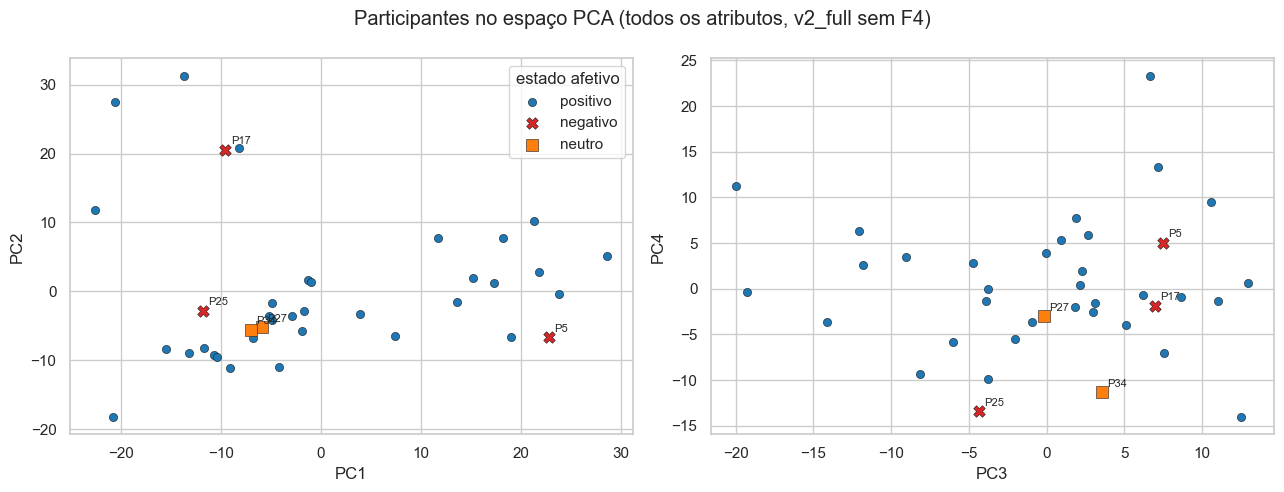

In [7]:
fs = B["v2_full_semF4"]["fs"]
Xp = to_pca(fs[B["v2_full_semF4"]["ALL"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (i, j) in zip(axes, [(0, 1), (2, 3)]):
    for lab_, mk, col in [("positivo", "o", "tab:blue"), ("negativo", "X", "tab:red"), ("neutro", "s", "tab:orange")]:
        m = fs.affect == lab_
        ax.scatter(Xp[m, i], Xp[m, j], marker=mk, c=col, s=70 if lab_ != "positivo" else 35,
                   label=lab_, edgecolor="k", linewidth=0.4)
    for s, x0, y0 in zip(fs.subject, Xp[:, i], Xp[:, j]):
        if s in NONPOS:
            ax.annotate(s, (x0, y0), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(f"PC{i + 1}"); ax.set_ylabel(f"PC{j + 1}")
axes[0].legend(title="estado afetivo")
fig.suptitle("Participantes no espaço PCA (todos os atributos, v2_full sem F4)")
fig.tight_layout(); fig.savefig(FIG / "09_afeto_pca.png", dpi=120)

## 4. Por atributo (exploratório)
Mann-Whitney positivo × não positivo, rank-biserial (**negativo = maior nos não positivos**) e FDR. Com 5 casos, o
menor p possível é ~0,002 e o poder é muito baixo: serve para apontar direções, não para concluir.
Inclui índices de lentificação por região e **assimetria frontal alfa** (log10 α direita − log10 α esquerda; > 0 = mais alfa à direita), clássica em
estudos de valência; F3/F4 não é usável (F4 com problema técnico), então usamos F8 − F7 e Fp2 − Fp1.

In [8]:
def extra_indices(fs, chs):
    reg = {"global": chs, "anterior": [c for c in chs if REGION[c] == "frontal"],
           "central": [c for c in chs if REGION[c] == "central"],
           "temporal": [c for c in chs if REGION[c] == "temporal"],
           "posterior": [c for c in chs if REGION[c] in ("parietal", "occipital")]}
    mean = lambda fam, cc: fs[[f"{fam}__{c}" for c in cc]].mean(axis=1)
    out = {}
    for r, cc in reg.items():
        dd, t, a, bb = (mean(f"rel_{x}", cc) for x in ["delta", "theta", "alpha", "beta"])
        out |= {f"delta_rel|{r}": dd, f"teta_rel|{r}": t, f"alfa_rel|{r}": a, f"beta_rel|{r}": bb,
                f"teta/alfa|{r}": mean("ratio_theta_alpha", cc), f"indice_lentificacao|{r}": (dd + t) / (a + bb),
                f"MNF_Hz|{r}": mean("num_MNF", cc)}
    for dr, es in [("F8", "F7"), ("Fp2", "Fp1")]:
        out[f"assim_alfa_{dr}-{es}|frontal"] = fs[f"abs_alpha__{dr}"] - fs[f"abs_alpha__{es}"]  # abs_* já em log10
    return pd.DataFrame(out)

mw_rows = []
for b in BASES:
    fs = B[b]["fs"]
    ind = extra_indices(fs, B[b]["CH"])
    r_ind = mann_whitney_fdr(ind, fs.affect_pos, a="nao_positivo", b="positivo").assign(base=b, conjunto="indices")
    r_all = mann_whitney_fdr(fs[B[b]["ALL"]], fs.affect_pos, a="nao_positivo", b="positivo").assign(base=b, conjunto="atributos")
    mw_rows += [r_ind, r_all]
    print(f"{b}: índices — menor q = {r_ind.q_fdr.min():.2f}; atributos ({len(B[b]['ALL'])}) — menor q = "
          f"{r_all.q_fdr.min():.2f}; nº com p < 0,05 = {(r_all.p < 0.05).sum()} (esperado ao acaso ≈ {0.05 * len(r_all):.0f})")
    B[b]["ind"] = ind
mw = pd.concat(mw_rows, ignore_index=True)
mw.to_csv(ROOT / "reports" / "09_afeto_atributos.csv", index=False)
display(mw[mw.conjunto == "indices"].sort_values("p").groupby("base").head(8).round(3))
display(mw[mw.conjunto == "atributos"].sort_values("p").groupby("base").head(8).round(3))

v2_full_semF4: índices — menor q = 0.04; atributos (864) — menor q = 0.70; nº com p < 0,05 = 22 (esperado ao acaso ≈ 43)


v0: índices — menor q = 0.33; atributos (912) — menor q = 1.00; nº com p < 0,05 = 14 (esperado ao acaso ≈ 46)


,feature,median_nao_positivo,median_positivo,rank_biserial,p,q_fdr,base,conjunto
0,teta_rel|posterior,0.186,0.128,-0.842,0.001,0.037,v2_full_semF4,indices
1,teta_rel|temporal,0.154,0.128,-0.721,0.008,0.128,v2_full_semF4,indices
901,teta_rel|posterior,0.181,0.136,-0.709,0.009,0.328,v0,indices
2,teta_rel|global,0.183,0.127,-0.697,0.010,0.128,v2_full_semF4,indices
902,teta_rel|temporal,0.150,0.126,-0.612,0.028,0.509,v0,indices
3,teta_rel|central,0.155,0.129,-0.600,0.031,0.288,v2_full_semF4,indices
4,teta_rel|anterior,0.190,0.131,-0.479,0.093,0.576,v2_full_semF4,indices
903,teta_rel|global,0.159,0.131,-0.479,0.093,0.722,v0,indices
904,alfa_rel|posterior,0.147,0.058,-0.479,0.093,0.722,v0,indices
5,alfa_rel|posterior,0.171,0.065,-0.455,0.112,0.576,v2_full_semF4,indices


,feature,median_nao_positivo,median_positivo,rank_biserial,p,q_fdr,base,conjunto
37,rel_theta__P4,0.179,0.123,-0.818,0.002,0.702,v2_full_semF4,atributos
38,rel_theta__O1,0.180,0.134,-0.818,0.002,0.702,v2_full_semF4,atributos
39,rel_theta__P3,0.190,0.129,-0.745,0.005,0.995,v2_full_semF4,atributos
938,num_SSC__C3,226.500,247.000,0.721,0.011,1.000,v0,atributos
939,rel_theta__P4,0.174,0.123,-0.685,0.012,1.000,v0,atributos
40,abs_delta__P4,-0.569,-0.121,0.673,0.014,0.995,v2_full_semF4,atributos
41,num_MVAL__P4,-0.005,-0.001,0.673,0.014,0.995,v2_full_semF4,atributos
940,rel_theta__P3,0.161,0.130,-0.661,0.016,1.000,v0,atributos
941,num_SSC__F8,237.500,255.000,0.679,0.017,1.000,v0,atributos
942,num_PKF__Pz,2.100,1.600,-0.648,0.018,1.000,v0,atributos


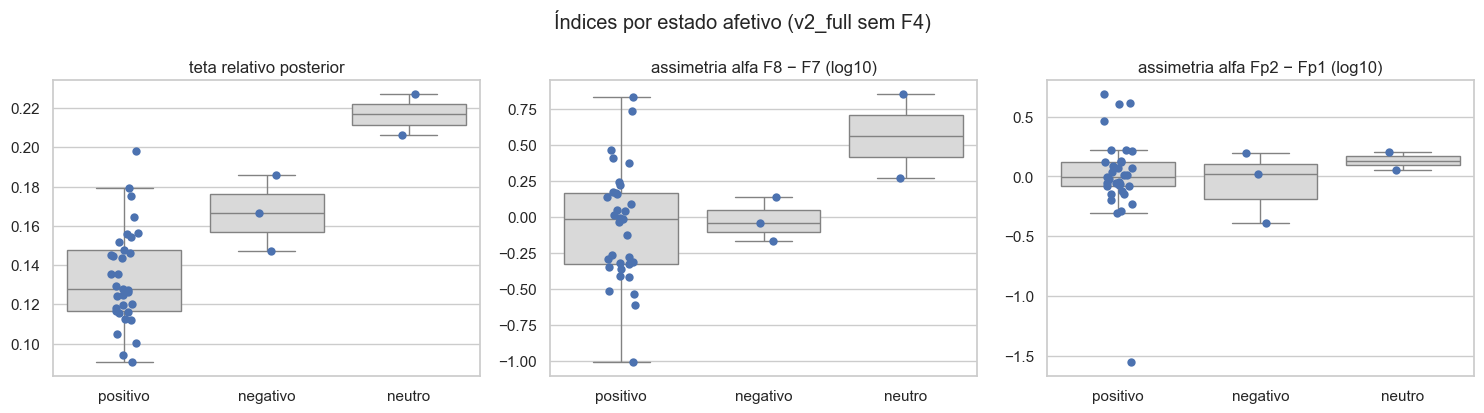

In [9]:
ind = B["v2_full_semF4"]["ind"].assign(afeto=B["v2_full_semF4"]["fs"].affect.values)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, t in [(axes[0], "teta_rel|posterior", "teta relativo posterior"),
                   (axes[1], "assim_alfa_F8-F7|frontal", "assimetria alfa F8 − F7 (log10)"),
                   (axes[2], "assim_alfa_Fp2-Fp1|frontal", "assimetria alfa Fp2 − Fp1 (log10)")]:
    sns.boxplot(data=ind, x="afeto", y=col, ax=ax, color="0.85", order=["positivo", "negativo", "neutro"], showfliers=False)
    sns.stripplot(data=ind, x="afeto", y=col, ax=ax, order=["positivo", "negativo", "neutro"], size=6)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Índices por estado afetivo (v2_full sem F4)")
fig.tight_layout(); fig.savefig(FIG / "09_afeto_indices.png", dpi=120)

### Robustez do achado em teta relativo posterior
O índice com menor p é o teta relativo posterior (maior nos não positivos). Antes de interpretar: (a) ele depende
de um único participante? (b) é explicado pela duração do relato (os não positivos falam menos) ou pelo diagnóstico?
(c) aparece nos negativos e nos neutros? Regressão linear sobre postos (robusta a outliers) com covariáveis.

In [10]:
def ols(y, X, names):
    """Mínimos quadrados com intercepto; retorna coeficientes e p-valores (t bilateral)."""
    A = np.column_stack([np.ones(len(y)), X])
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - A @ beta
    dof = len(y) - A.shape[1]
    se = np.sqrt(np.diag(res @ res / dof * np.linalg.inv(A.T @ A)))
    pv = 2 * stats.t.sf(np.abs(beta / se), dof)
    return dict(zip(["intercepto"] + names, beta)), dict(zip(["intercepto"] + names, pv))

rob_rows = []
for b in BASES:
    fs = B[b]["fs"]
    df = pd.DataFrame({"teta_post": B[b]["ind"]["teta_rel|posterior"].values, "subject": fs.subject.values,
                       "nao_pos": (fs.affect_pos == "nao_positivo").astype(int).values,
                       "tcm": (fs.group == "TCM").astype(int).values, "afeto": fs.affect.values})
    df["log_dur"] = np.log(inv.duration_s.loc[df.subject].values)
    rho, p_rho = stats.spearmanr(df.teta_post, df.log_dur)
    df["r_teta"] = stats.rankdata(df.teta_post)
    coef, pv = ols(df.r_teta.to_numpy(float), df[["nao_pos", "tcm", "log_dur"]].to_numpy(float), ["nao_pos", "tcm", "log_dur"])
    loo = []
    for s_ in NONPOS:
        d_ = df[df.subject != s_]
        loo.append(stats.mannwhitneyu(d_.teta_post[d_.nao_pos == 1], d_.teta_post[d_.nao_pos == 0]).pvalue)
    rob_rows.append({"base": b, "spearman_com_log_duracao": rho, "p_spearman": p_rho,
                     "coef_nao_pos_postos": coef["nao_pos"], "p_nao_pos_ajustado": pv["nao_pos"],
                     "p_tcm_ajustado": pv["tcm"], "p_log_dur_ajustado": pv["log_dur"],
                     "p_MW_sem_cada_nao_pos(max)": max(loo),
                     "mediana_negativo": df.teta_post[df.afeto == "negativo"].median(),
                     "mediana_neutro": df.teta_post[df.afeto == "neutro"].median(),
                     "mediana_positivo": df.teta_post[df.afeto == "positivo"].median(),
                     "valores_nao_pos": str(df.loc[df.nao_pos == 1].set_index("subject").teta_post.round(3).to_dict())})
rob = pd.DataFrame(rob_rows)
rob.to_csv(ROOT / "reports" / "09_afeto_robustez_teta.csv", index=False)
display(rob.T)

,0,1
base,v2_full_semF4,v0
spearman_com_log_duracao,-0.282197,-0.216982
p_spearman,0.086061,0.19069
coef_nao_pos_postos,15.324056,13.003577
p_nao_pos_ajustado,0.003964,0.01792
p_tcm_ajustado,0.530162,0.855309
p_log_dur_ajustado,0.445145,0.691283
p_MW_sem_cada_nao_pos(max),0.005875,0.039125
mediana_negativo,0.166624,0.149199
mediana_neutro,0.216825,0.194846


## 5. Referência supervisionada (descritiva)
Regressão logística LOSO (mesma do notebook 05) para positivo × não positivo. Com 5 casos minoritários a AUC é muito
instável; o IC95% (bootstrap) e um teste de permutação (100 embaralhamentos do rótulo) mostram o quanto.

In [11]:
sup_rows = []
for b in BASES:
    fs = B[b]["fs"]
    yb = (fs.affect_pos == "nao_positivo").astype(int).to_numpy()
    for name, X in [("todos", fs[B[b]["ALL"]]), ("classicos", fs[B[b]["CLASS"]]), ("indices", B[b]["ind"])]:
        p = loso_logreg(X, yb)
        auc = roc_auc_score(yb, p); lo, hi = auc_ci(yb, p)
        null = [roc_auc_score(yp, loso_logreg(X, yp)) for yp in (rng.permutation(yb) for _ in range(100))]
        sup_rows.append({"base": b, "atributos": name, "AUC": auc, "IC95": f"{lo:.2f}–{hi:.2f}",
                         "p_perm": (np.sum(np.array(null) >= auc) + 1) / 101})
sup = pd.DataFrame(sup_rows)
sup.to_csv(ROOT / "reports" / "09_afeto_supervisionado.csv", index=False)
display(sup.round(3))

,base,atributos,AUC,IC95,p_perm
0,v2_full_semF4,todos,0.552,0.23–0.89,0.465
1,v2_full_semF4,classicos,0.582,0.14–0.97,0.257
2,v2_full_semF4,indices,0.636,0.24–0.97,0.208
3,v0,todos,0.552,0.25–0.87,0.327
4,v0,classicos,0.533,0.18–0.96,0.327
5,v0,indices,0.600,0.25–0.94,0.218


## 6. Projeções 2D das janelas: grupo, participante e estado afetivo
Matriz 3 × 3 (PCA, t-SNE, UMAP × grupo, participante, estado afetivo) na base principal, com todas as janelas e
todos os atributos (padronização global). Para não depender só do olhar, mede-se a **concordância de vizinhança**:
entre os 10 vizinhos mais próximos de cada janela (no espaço PCA de 50 componentes, onde t-SNE e UMAP são
calculados), a fração que tem o mesmo rótulo, comparada com a fração esperada ao acaso (Σ pᵢ²). Repetido com
z-score dentro de cada participante, que remove o nível individual.

,normalizacao,rotulo,vizinhos_mesmo_rotulo,esperado_acaso,razao
0,padronizacao_global,grupo,0.990,0.596,1.661
1,padronizacao_global,participante,0.981,0.042,23.254
2,padronizacao_global,estado_afetivo,0.996,0.851,1.171
3,zscore_intra_participante,grupo,0.657,0.596,1.102
4,zscore_intra_participante,participante,0.216,0.042,5.121
5,zscore_intra_participante,estado_afetivo,0.879,0.851,1.033


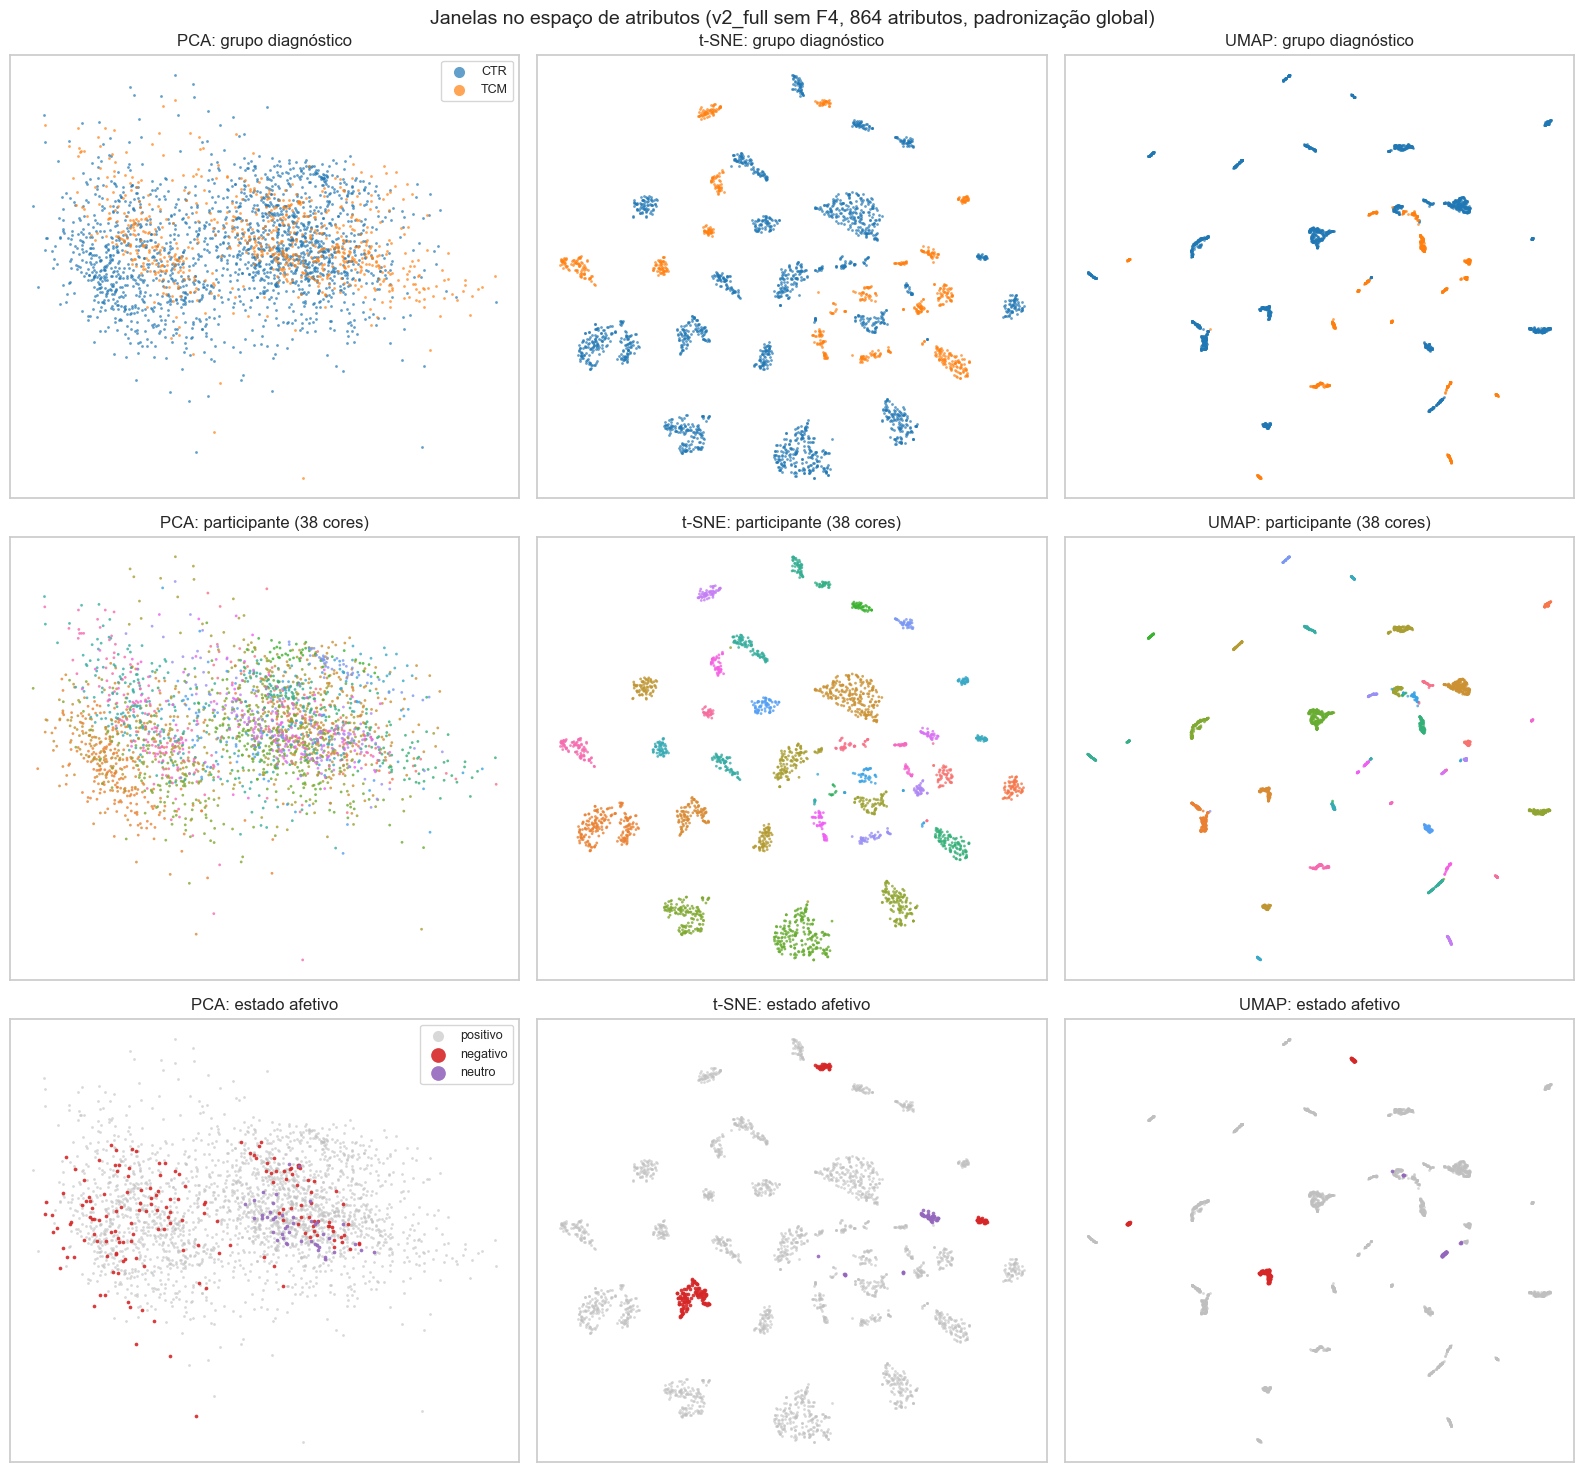

In [12]:
import umap
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

fw = B["v2_full_semF4"]["fw"].copy()
cols = B["v2_full_semF4"]["ALL"]
fw["afeto"] = fw.subject.map(AFF).values
Xg = StandardScaler().fit_transform(fw[cols])
Xs = fw.groupby("subject")[cols].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9)).to_numpy()

def neighbor_agreement(Z, labels, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)[1][:, 1:]
    lab = np.asarray(labels)
    obs = (lab[idx] == lab[:, None]).mean()
    p = pd.Series(lab).value_counts(normalize=True)
    return obs, float((p ** 2).sum())

na_rows = []
for nome, X in [("padronizacao_global", Xg), ("zscore_intra_participante", Xs)]:
    Z50 = PCA(50, random_state=SEED).fit_transform(X)
    for rot, labs in [("grupo", fw.group), ("participante", fw.subject), ("estado_afetivo", fw.afeto)]:
        obs, chance = neighbor_agreement(Z50, labs)
        na_rows.append({"normalizacao": nome, "rotulo": rot, "vizinhos_mesmo_rotulo": obs, "esperado_acaso": chance,
                        "razao": obs / chance})
na = pd.DataFrame(na_rows)
na.to_csv(ROOT / "reports" / "09_vizinhanca_projecoes.csv", index=False)
display(na.round(3))

Z50 = PCA(50, random_state=SEED).fit_transform(Xg)
E = {"PCA": Z50[:, :2],
     "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z50),
     "UMAP": umap.UMAP(random_state=SEED).fit_transform(Z50)}

subj_order = sorted(fw.subject.unique(), key=lambda s: int(s[1:]))
pal_subj = dict(zip(subj_order, sns.color_palette("husl", len(subj_order))))
pal_grp = {"CTR": "tab:blue", "TCM": "tab:orange"}
pal_aff = {"positivo": "0.75", "negativo": "tab:red", "neutro": "tab:purple"}

fig, axes = plt.subplots(3, 3, figsize=(16, 15))
for j, (ename, Z) in enumerate(E.items()):
    ax = axes[0, j]
    for g, c in pal_grp.items():
        m = (fw.group == g).to_numpy()
        ax.scatter(Z[m, 0], Z[m, 1], s=4, c=c, label=g, alpha=0.7, linewidths=0)
    ax.set_title(f"{ename}: grupo diagnóstico")
    ax = axes[1, j]
    ax.scatter(Z[:, 0], Z[:, 1], s=4, c=[pal_subj[s] for s in fw.subject], alpha=0.8, linewidths=0)
    ax.set_title(f"{ename}: participante (38 cores)")
    ax = axes[2, j]
    for a in ["positivo", "negativo", "neutro"]:   # não positivos desenhados por cima
        m = (fw.afeto == a).to_numpy()
        ax.scatter(Z[m, 0], Z[m, 1], s=4 if a == "positivo" else 7, c=pal_aff[a], label=a,
                   alpha=0.6 if a == "positivo" else 0.9, linewidths=0)
    ax.set_title(f"{ename}: estado afetivo")
for i in (0, 2):
    axes[i, 0].legend(markerscale=4, loc="best", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Janelas no espaço de atributos (v2_full sem F4, 864 atributos, padronização global)", fontsize=14)
fig.tight_layout(); fig.savefig(FIG / "09_embed_grupo_participante_afeto.png", dpi=110)